# Dry Bean Classification; Data Audit and Baseline

The goal of this project is to use morphological measurements of dry beans to classify each bean into one of 7 varieties.

## Imports and Setup

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42

## Dataset Loading

In [2]:
# Support running from either the project root or the notebooks directory.
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

dataset_path = project_dir / "data" / "raw" / "Dry_Bean_Dataset.xlsx"
df = pd.read_excel(dataset_path, sheet_name="Dry_Beans_Dataset")

df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## Initial Dataset Inspection

These checks inspect the structure and target labels of the loaded dataset without changing it.

Check the shape to identify the number of rows and columns.

In [3]:
df.shape

(13611, 17)

List all column names to identify the available measurements and target column.

In [4]:
df.columns.tolist()

['Area',
 'Perimeter',
 'MajorAxisLength',
 'MinorAxisLength',
 'AspectRation',
 'Eccentricity',
 'ConvexArea',
 'EquivDiameter',
 'Extent',
 'Solidity',
 'roundness',
 'Compactness',
 'ShapeFactor1',
 'ShapeFactor2',
 'ShapeFactor3',
 'ShapeFactor4',
 'Class']

Display the first five rows to see how individual records and their labels are represented.

In [5]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Inspect the pandas data type of each column to check how the spreadsheet values were loaded.

In [6]:
df.dtypes

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str
dtype: object

Use `info()` to summarise the columns, non-null counts, data types and memory usage.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

Identify and display the target column name used for bean variety labels.

In [8]:
target_column = "Class"
target_column

'Class'

Inspect the unique target values to identify the variety labels present in the dataset.

In [9]:
df[target_column].unique()

<StringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str

Count the distinct non-missing target labels to check the number of classes.

In [10]:
df[target_column].nunique()

7

## Data Quality Audit

This checks for any issues that could affect results before I make any cleaning or preprocessing decisions.

### Missing values

Checking for missing values in each column and across the whole dataset. This check only reports missing values

In [11]:
df.isna().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [12]:
df.isna().sum().sum()

np.int64(0)

### Duplicate rows

Checking for exact duplicate rows, because any repeated records might make the model less reliable by affecting the train/test split.

In [13]:
df.duplicated().sum()

np.int64(68)

### Class distribution

Checking the no. of records in each bean class to see if the target classes are represented evenly, or if some varieties are over/under represented.

In [14]:
df[target_column].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [15]:
df[target_column].value_counts(normalize=True).mul(100).round(2)

Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: proportion, dtype: float64

### Numerical feature summary

This summarises all the numerical predictor columns using count, mean, standard deviation, minimum, quartiles and maximum. This gives an overview of ranges and distribution to show any overly large or smaller values that imght need to be inspected later on

In [16]:
df.select_dtypes(include="number").describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


## Data Preparation

68 duplicate rows were found during the audit, so I removed those before the data gets split for modelling. There were no missing values, so imputation isn't needed


In [17]:
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

Original dataset shape: (13611, 17)
Cleaned dataset shape: (13543, 17)
Rows removed: 68


Some features have fairly extreme values, but those measurements aren't necessarily incorrect, so I won't remove them for now.

The cleaned data is separated into the input features and the target variable. `Class` is used as the target, while the remaining columns are used aspredictor features.

In [18]:
X = df_clean.drop(columns=[target_column])
y = df_clean[target_column]

print("X.shape:", X.shape)
print("y.shape:", y.shape)
print("Class present in X.columns:", "Class" in X.columns)

X.shape: (13543, 16)
y.shape: (13543,)
Class present in X.columns: False


## Evaluation Design

The cleaned dataset is split into training and test sets with 80% used for training and 20% kept aside for testing. I used a stratified split because the class reperesentation isn't even. This keeps the class proportions in the training and test sets close to those in the full dataset.

The test set will be kept separate while the models are being developed. This avoids using test data to influence preprocessing or model choices and gives a fairer final evaluation

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train.shape:", X_train.shape)
print("X_test.shape:", X_test.shape)
print("y_train.shape:", y_train.shape)
print("y_test.shape:", y_test.shape)

X_train.shape: (10834, 16)
X_test.shape: (2709, 16)
y_train.shape: (10834,)
y_test.shape: (2709,)


The class percentages in the full dataset, training set and test set are compared to check that stratification kept the class distribution roughly the same in each set.

In [20]:
class_percentages = pd.DataFrame({
    "y (%)": y.value_counts(normalize=True) * 100,
    "y_train (%)": y_train.value_counts(normalize=True) * 100,
    "y_test (%)": y_test.value_counts(normalize=True) * 100
})

class_percentages.round(2)

,y (%),y_train (%),y_test (%)
Class,,,
DERMASON,26.18,26.19,26.17
SIRA,19.46,19.47,19.45
SEKER,14.97,14.96,14.99
HOROZ,13.73,13.73,13.73
CALI,12.04,12.04,12.03
BARBUNYA,9.76,9.76,9.78
BOMBAY,3.85,3.86,3.84


## Training Data Exploration

I used only the training data for this section so that the test set stays separate until the final evaluation. The training class distribution is plotted below to show how many examples there are for each bean variety. Dermason has the most training examples, while Bombay has fewer than the other classes.

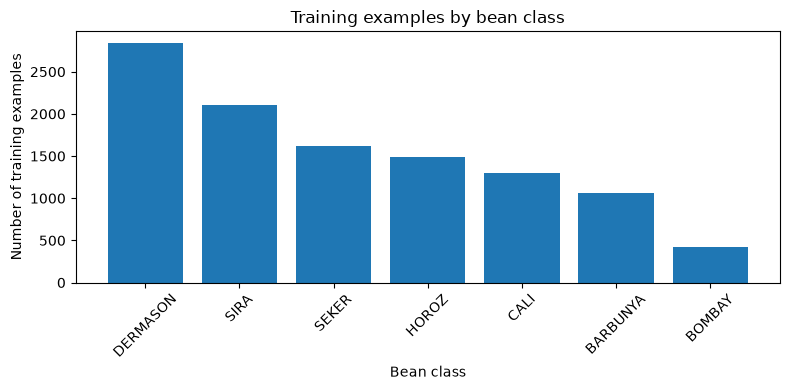

In [21]:
class_counts = y_train.value_counts()

plt.figure(figsize=(8, 4))
plt.bar(class_counts.index, class_counts.values)
plt.title("Training examples by bean class")
plt.xlabel("Bean class")
plt.ylabel("Number of training examples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

I looked at four of the numerical features (Area, Perimeter, AspectRation and Compactness) to get a better idea of how their values are distributed in the training data. The plots show that the features do not all follow the same distribution. In particular, Area and Perimeter contain a smaller number of much larger values compared with most of the observations.

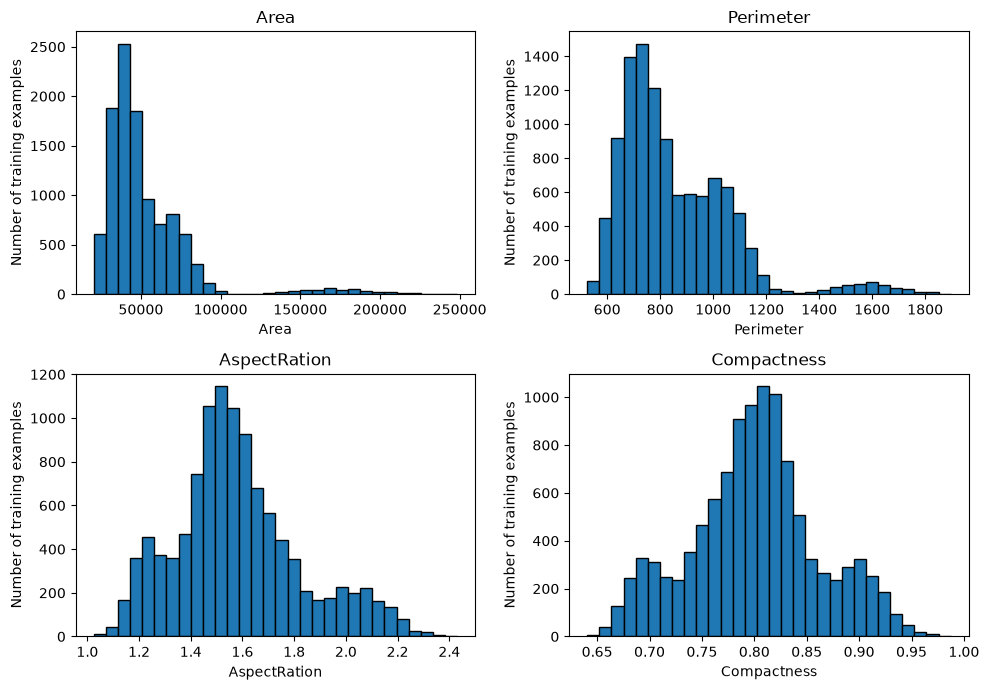

In [22]:
exploration_features = ["Area", "Perimeter", "AspectRation", "Compactness"]

for feature in exploration_features:
    if feature not in X_train.columns:
        raise ValueError(f"Column not found in training data: {feature}")

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.flat, exploration_features):
    ax.hist(X_train[feature], bins=30, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of training examples")

plt.tight_layout()
plt.show()

Boxplots were also used to check for values that are far outside the main range of each feature. There are some potential outliers, especially for Area and Perimeter, but those values are kept in the dataset because there's no evidence that they're incorrect measurements.

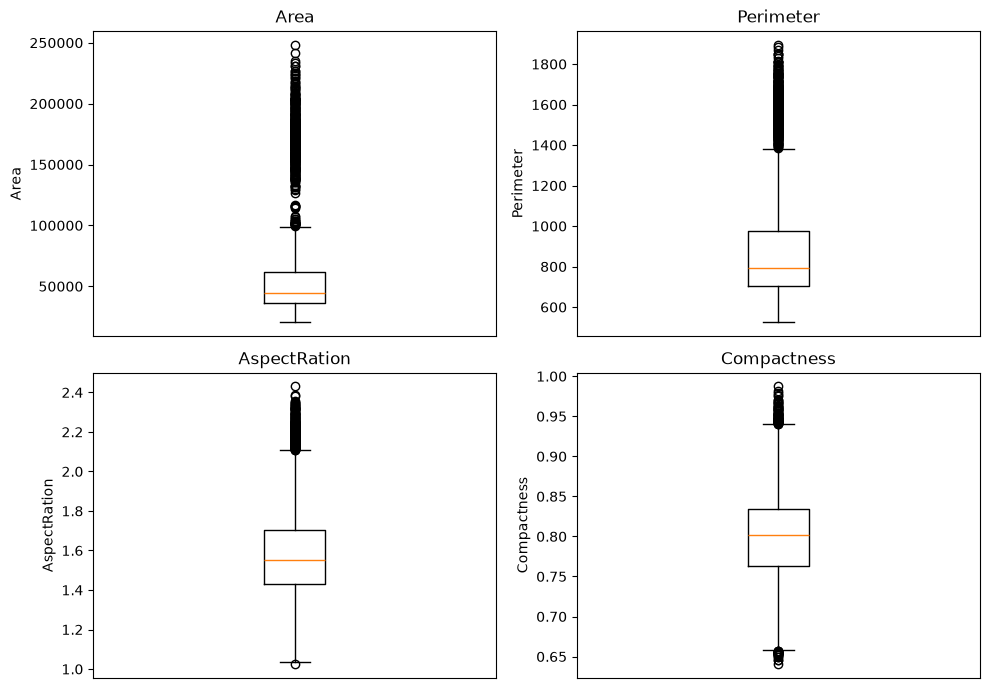

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.flat, exploration_features):
    ax.boxplot(X_train[feature])
    ax.set_title(feature)
    ax.set_ylabel(feature)
    ax.set_xticks([])

plt.tight_layout()
plt.show()